<a href="https://colab.research.google.com/github/swapnasaina274/malicious-mobile-app-detection/blob/main/01_Machine_Learning_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

In [2]:
!pip install lightgbm catboost xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 47.6 MB/s  0:00:02


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Data Splitting, Scaling & Selection Utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
# Classification Model Suite
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    fbeta_score,
    classification_report,
    confusion_matrix
)
# Serialization Utilities for Model Saving
import joblib
import json
from google.colab import drive, files

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Updated file path including the subfolder

# Load the CICMalDroid 2020 dataset

file_path = "/content/drive/MyDrive/Malicious project work/feature_vectors_syscallsbinders_frequency_5_Cat.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 11598
Number of columns: 471


In [5]:
# Display the first 5 rows
df.head()

,ACCESS_PERSONAL_INFO___,ALTER_PHONE_STATE___,ANTI_DEBUG_____,CREATE_FOLDER_____,CREATE_PROCESS`_____,CREATE_THREAD_____,DEVICE_ACCESS_____,EXECUTE_____,FS_ACCESS____,FS_ACCESS()____,...,utimes,vfork,vibrate,vibratePattern,wait4,watchRotation,windowGainedFocus,write,writev,Class
0,1,0,0,3,0,14,2,0,3,0,...,0,0,0,0,0,0,0,37,10,1
1,3,0,0,6,0,42,91,0,32,0,...,0,0,0,0,0,0,2,2838,46,1
2,2,0,0,4,0,23,3,0,17,2,...,0,0,0,0,0,0,1,111,20,1
3,1,0,0,4,0,27,9,0,36,0,...,0,0,0,0,0,0,7,987,197,1
4,3,0,0,11,0,18,3,0,16,0,...,0,0,0,0,0,0,1,98,25,1


In [6]:
# Display all column names
print("Total columns:", len(df.columns))

for i, column in enumerate(df.columns):
    print(i, ":", column)

Total columns: 471
0 : ACCESS_PERSONAL_INFO___
1 : ALTER_PHONE_STATE___
2 : ANTI_DEBUG_____
3 : CREATE_FOLDER_____
4 : CREATE_PROCESS`_____
5 : CREATE_THREAD_____
6 : DEVICE_ACCESS_____
7 : EXECUTE_____
8 : FS_ACCESS____
9 : FS_ACCESS()____
10 : FS_ACCESS(CREATE)____
11 : FS_ACCESS(CREATE__APPEND)__
12 : FS_ACCESS(CREATE__READ)__
13 : FS_ACCESS(CREATE__READ__WRITE)
14 : FS_ACCESS(CREATE__WRITE)__
15 : FS_ACCESS(CREATE__WRITE__APPEND)
16 : FS_ACCESS(READ)____
17 : FS_ACCESS(READ__WRITE)__
18 : FS_ACCESS(WRITE)____
19 : FS_PIPE_ACCESS___
20 : FS_PIPE_ACCESS()___
21 : FS_PIPE_ACCESS(READ)___
22 : FS_PIPE_ACCESS(READ__)_
23 : FS_PIPE_ACCESS(READ__WRITE)_
24 : FS_PIPE_ACCESS(WRITE)___
25 : NETWORK_ACCESS____
26 : NETWORK_ACCESS()____
27 : NETWORK_ACCESS(READ)____
28 : NETWORK_ACCESS(READ__WRITE)__
29 : NETWORK_ACCESS(READ__WRITE__)
30 : NETWORK_ACCESS(WRITE)____
31 : NETWORK_ACCESS(WRITE__)__
32 : SMS_SEND____
33 : TERMINATE_PROCESS
34 : TERMINATE_THREAD
35 : __arm_nr_cacheflush
36 : __arm_

In [7]:
# Check the distribution of target variable 'Class'
class_counts = df['Class'].value_counts().sort_index()
print("Class Distribution:")
print(class_counts)

Class Distribution:
Class
1    1253
2    2100
3    3904
4    2546
5    1795
Name: count, dtype: int64


In [8]:
# 1. Map numerical target labels to actual malware categories
class_mapping = {
    1: "Adware",
    2: "Banking",
    3: "SMS Malware",
    4: "Riskware",
    5: "Benign"
}
# 1. Map numerical labels to actual class names
df["Class_Name"] = df["Class"].map(class_mapping)

# 2. Generate unified class distribution summary table
class_counts = df["Class_Name"].value_counts()

class_summary = pd.DataFrame({
    'Class ID': list(class_mapping.keys()),
    'Category': list(class_mapping.values()),
    'Count': [class_counts[name] for name in class_mapping.values()],
    'Percentage (%)': [(class_counts[name] / len(df) * 100).round(2) for name in class_mapping.values()]
}).set_index('Class ID')

print(class_summary)

             Category  Count  Percentage (%)
Class ID                                    
1              Adware   1253           10.80
2             Banking   2100           18.11
3         SMS Malware   3904           33.66
4            Riskware   2546           21.95
5              Benign   1795           15.48


In [9]:
# Check for missing values

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nColumns containing missing values:")
print(missing_values[missing_values > 0])


Total missing values: 0

Columns containing missing values:
Series([], dtype: int64)


In [10]:
# Check for duplicate rows

duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 72


In [11]:
# Remove duplicate rows

df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("Cleaned shape:", df.shape)

print("Updated Class Distribution:")
print(df["Class_Name"].value_counts())

Duplicates removed successfully!
Cleaned shape: (11526, 472)
Updated Class Distribution:
Class_Name
SMS Malware    3903
Riskware       2534
Banking        2044
Benign         1792
Adware         1253
Name: count, dtype: int64


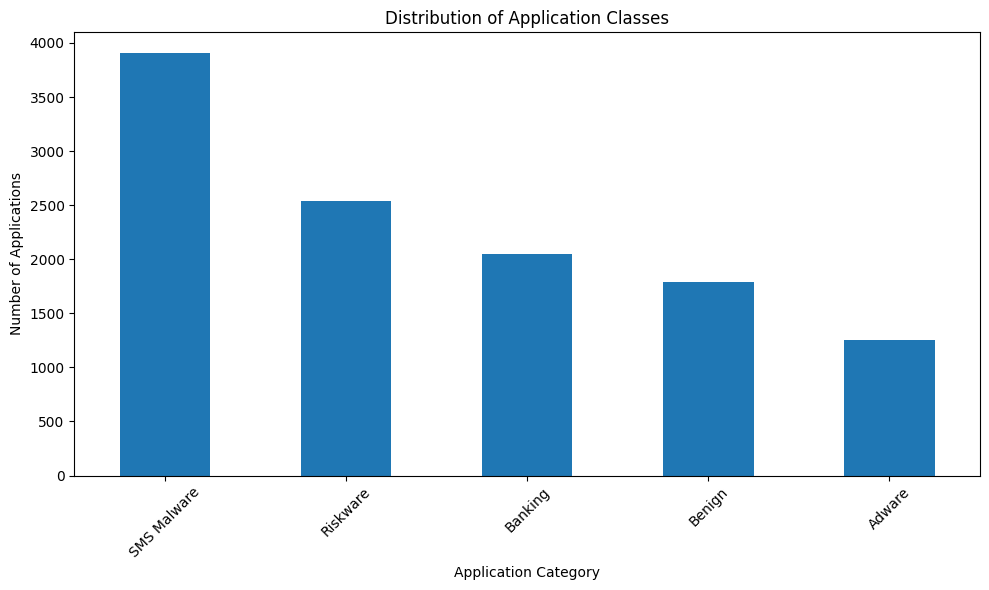

In [12]:
# STEP 2: EXPLORATORY DATA ANALYSIS (EDA)


import matplotlib.pyplot as plt

# Visualize the distribution of application classes
plt.figure(figsize=(10, 6))

df["Class_Name"].value_counts().plot(kind="bar")

plt.title("Distribution of Application Classes")
plt.xlabel("Application Category")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [13]:
# Statistical summary of the numerical features

print("Statistical Summary of the Dataset:")
display(df.describe())

Statistical Summary of the Dataset:


,ACCESS_PERSONAL_INFO___,ALTER_PHONE_STATE___,ANTI_DEBUG_____,CREATE_FOLDER_____,CREATE_PROCESS`_____,CREATE_THREAD_____,DEVICE_ACCESS_____,EXECUTE_____,FS_ACCESS____,FS_ACCESS()____,...,utimes,vfork,vibrate,vibratePattern,wait4,watchRotation,windowGainedFocus,write,writev,Class
count,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,...,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,11526.000000,1.152600e+04,11526.000000
mean,57.790908,0.001215,0.044855,5.817283,0.990023,29.929724,29.820319,2.265053,74.103332,6.730175,...,0.093875,2.243797,0.001822,0.000694,6.491845,0.000694,1.658164,1077.795332,1.046051e+03,3.136040
std,445.511577,0.055876,1.107725,10.403308,4.073808,32.205766,268.478022,9.898247,219.691335,20.105990,...,1.813960,15.738632,0.070303,0.029448,164.790110,0.026337,9.957346,6170.094438,1.718172e+04,1.198143
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,1.000000
25%,0.000000,0.000000,0.000000,2.000000,0.000000,10.000000,2.000000,0.000000,8.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,74.000000,1.200000e+01,2.000000
50%,2.000000,0.000000,0.000000,3.000000,0.000000,17.000000,3.000000,0.000000,21.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,257.000000,4.400000e+01,3.000000
75%,8.000000,0.000000,0.000000,6.000000,0.000000,39.000000,22.000000,0.000000,53.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1152.000000,1.450000e+02,4.000000
max,7647.000000,5.000000,91.000000,700.000000,140.000000,1332.000000,26631.000000,399.000000,8380.000000,1192.000000,...,113.000000,117.000000,6.000000,2.000000,17431.000000,1.000000,1042.000000,490069.000000,1.301356e+06,5.000000


In [14]:
# Check the number of rows and columns
print("Cleaned dataset shape:", df.shape)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

# Display the first five rows
display(df.head())

Cleaned dataset shape: (11526, 472)
Total rows: 11526
Total columns: 472


,ACCESS_PERSONAL_INFO___,ALTER_PHONE_STATE___,ANTI_DEBUG_____,CREATE_FOLDER_____,CREATE_PROCESS`_____,CREATE_THREAD_____,DEVICE_ACCESS_____,EXECUTE_____,FS_ACCESS____,FS_ACCESS()____,...,vfork,vibrate,vibratePattern,wait4,watchRotation,windowGainedFocus,write,writev,Class,Class_Name
0,1,0,0,3,0,14,2,0,3,0,...,0,0,0,0,0,0,37,10,1,Adware
1,3,0,0,6,0,42,91,0,32,0,...,0,0,0,0,0,2,2838,46,1,Adware
2,2,0,0,4,0,23,3,0,17,2,...,0,0,0,0,0,1,111,20,1,Adware
3,1,0,0,4,0,27,9,0,36,0,...,0,0,0,0,0,7,987,197,1,Adware
4,3,0,0,11,0,18,3,0,16,0,...,0,0,0,0,0,1,98,25,1,Adware


In [15]:
class_counts = df["Class_Name"].value_counts()

class_summary = pd.DataFrame({
    'Class ID': list(class_mapping.keys()),
    'Category': list(class_mapping.values()),
    'Count': [class_counts[name] for name in class_mapping.values()],
    'Percentage (%)': [(class_counts[name] / len(df) * 100).round(2) for name in class_mapping.values()]
}).set_index('Class ID')

In [16]:

# STEP 3: FEATURE MATRIX & TARGET SEPARATION


# 1. Isolate the feature matrix (X) by dropping target columns
X = df.drop(columns=["Class", "Class_Name"])

# 2. Isolate the target label vector (y)
y = df["Class"]

# Verify dimensions
print("--- Feature & Target Separation Complete ---")
print(f"Feature Matrix Shape (X) : {X.shape} (11,526 samples, 470 features)")
print(f"Target Vector Shape (y)  : {y.shape} (11,526 target labels)")

--- Feature & Target Separation Complete ---
Feature Matrix Shape (X) : (11526, 470) (11,526 samples, 470 features)
Target Vector Shape (y)  : (11526,) (11,526 target labels)


In [17]:
# STEP 4: THREE-WAY STRATIFIED DATA SPLITTING

from sklearn.model_selection import train_test_split

# 1. First Split: 70% Temporary (Train + Validation) and 30% Unseen Test Set
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 2. Second Split: Divide 70% Temp into 60% Train and 10% Validation (10/70 = ~14.29%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=(10/70), random_state=42, stratify=y_temp
)

# Verify Split Dimensions and Percentages
print("--- Data Splitting Complete ---")
print(f"Training Set   (X_train) : {X_train.shape} ({len(X_train)/len(df)*100:.2f}%)")
print(f"Validation Set (X_val)   : {X_val.shape} ({len(X_val)/len(df)*100:.2f}%)")
print(f"Test Set       (X_test)  : {X_test.shape} ({len(X_test)/len(df)*100:.2f}%)")

# Verify Stratified Class Distribution on Training Set
print("\nTraining Set Target Distribution (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))

--- Data Splitting Complete ---
Training Set   (X_train) : (6915, 470) (59.99%)
Validation Set (X_val)   : (1153, 470) (10.00%)
Test Set       (X_test)  : (3458, 470) (30.00%)

Training Set Target Distribution (%):
Class
1    10.87
2    17.73
3    33.87
4    21.98
5    15.55
Name: proportion, dtype: float64


In [18]:
# STEP 5: FEATURE IMPORTANCE ANALYSIS (TRAINING SET ONLY)

from sklearn.ensemble import RandomForestClassifier
import pandas as pd

# 1. Audit zero-variance features on X_train for data profiling
train_variances = X_train.var()
zero_var_features = train_variances[train_variances == 0].index.tolist()
print(f"Zero-variance features in X_train: {len(zero_var_features)}")

# 2. Fit Random Forest on X_train to compute feature importance scores
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_selector.fit(X_train, y_train)

# 3. Extract and display Top 20 Most Important Features
importances = pd.Series(rf_selector.feature_importances_, index=X_train.columns)
top_20_features = importances.sort_values(ascending=False).head(20)

print("\n--- Top 20 Feature Importance Ranking (All 470 Features Retained) ---")
print(top_20_features)

Zero-variance features in X_train: 29

--- Top 20 Feature Importance Ranking (All 470 Features Retained) ---
pread64                    0.023937
access                     0.018663
getInstallerPackageName    0.018090
ACCESS_PERSONAL_INFO___    0.017921
getDisplayInfo             0.017267
mkdir                      0.015488
gettimeofday               0.015081
mmap2                      0.014778
lstat64                    0.014723
statfs64                   0.014391
munmap                     0.014240
getPackageInfo             0.013877
CREATE_FOLDER_____         0.013761
stat64                     0.013450
read                       0.013016
mprotect                   0.012844
close                      0.012618
clock_gettime              0.012571
getDeviceId                0.012441
sigprocmask                0.012356
dtype: float64


In [19]:
# STEP 6: FEATURE SCALING (ALL 470 FEATURES)


from sklearn.preprocessing import StandardScaler

# 1. Initialize the StandardScaler
scaler = StandardScaler()

# 2. Fit scaler strictly on X_train and transform training set
X_train_scaled = scaler.fit_transform(X_train)

# 3. Transform Validation and Test sets using fitted training parameters
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Verify scaled array dimensions
print("--- Feature Scaling Complete ---")
print(f"X_train_scaled shape : {X_train_scaled.shape}")
print(f"X_val_scaled shape   : {X_val_scaled.shape}")
print(f"X_test_scaled shape  : {X_test_scaled.shape}")

--- Feature Scaling Complete ---
X_train_scaled shape : (6915, 470)
X_val_scaled shape   : (1153, 470)
X_test_scaled shape  : (3458, 470)


In [20]:
# STEP 7: MODEL TRAINING & VALIDATION SELECTION

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import accuracy_score, precision_recall_fscore_support, fbeta_score

# 1. Align target labels to 0-4 for gradient boosting compatibility
y_train_encoded = y_train - 1
y_val_encoded = y_val - 1

# 2. Define the Multi-Model Suite
models = {
    "Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='mlogloss'),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=100, learning_rate=0.1, random_seed=42, verbose=0)
}

validation_results = []

# 3. Train each model and evaluate on the Validation set
for name, model in models.items():
    if name == "Logistic Regression (Baseline)":
        # Logistic Regression uses scaled features and original 1-5 labels
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_val_scaled)
        y_true = y_val
    else:
        # Tree ensembles use raw feature matrix (470 features) and 0-indexed labels (0-4)
        model.fit(X_train, y_train_encoded)
        preds = model.predict(X_val)
        y_true = y_val_encoded

    # Calculate evaluation metrics
    acc = accuracy_score(y_true, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, preds, average='weighted')
    f05 = fbeta_score(y_true, preds, beta=0.5, average='weighted')

    validation_results.append({
        "Model": name,
        "Validation Accuracy (%)": round(acc * 100, 2),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "F0.5-Score": round(f05, 4)
    })

# 4. Display Comparison Summary Table
summary_df = pd.DataFrame(validation_results)
print("--- Validation Set Multi-Model Performance Comparison ---")
print(summary_df.to_string(index=False))

--- Validation Set Multi-Model Performance Comparison ---
                         Model  Validation Accuracy (%)  Precision  Recall  F1-Score  F0.5-Score
Logistic Regression (Baseline)                    86.21     0.8617  0.8621    0.8598      0.8605
                 Random Forest                    94.36     0.9446  0.9436    0.9437      0.9442
                       XGBoost                    94.28     0.9438  0.9428    0.9429      0.9434
                      LightGBM                    95.23     0.9527  0.9523    0.9523      0.9525
                      CatBoost                    92.02     0.9215  0.9202    0.9199      0.9207


     FINAL TEST SET CLASSIFICATION REPORT (CHAMPION LIGHTGBM)     
              precision    recall  f1-score   support

      Adware     0.8843    0.9149    0.8993       376
     Banking     0.9562    0.9250    0.9403       613
 SMS Malware     0.9831    0.9923    0.9877      1171
    Riskware     0.9493    0.9368    0.9430       760
      Benign     0.9393    0.9498    0.9445       538

    accuracy                         0.9532      3458
   macro avg     0.9424    0.9438    0.9430      3458
weighted avg     0.9533    0.9532    0.9532      3458



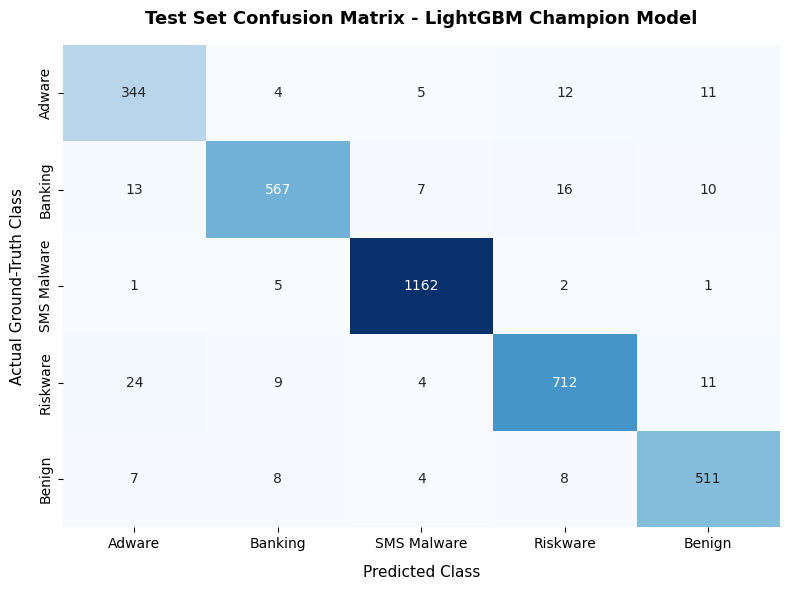

In [21]:
# STEP 8: FINAL EVALUATION ON UNSEEN TEST SET


import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from lightgbm import LGBMClassifier

# 1. Initialize and Fit Champion LightGBM Model on Training Data
champion_model = LGBMClassifier(
    n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, verbose=-1
)

# Encode targets (0-4) for LightGBM compatibility
y_train_encoded = y_train - 1
y_test_encoded = y_test - 1

# Train strictly on X_train (470 features)
champion_model.fit(X_train, y_train_encoded)

# 2. Predict on the completely unseen Test Set (X_test)
y_test_pred = champion_model.predict(X_test)

# Class name mapping for display
class_names = ["Adware", "Banking", "SMS Malware", "Riskware", "Benign"]

# 3. Print Detailed Classification Report

print("     FINAL TEST SET CLASSIFICATION REPORT (CHAMPION LIGHTGBM)     ")
print(classification_report(y_test_encoded, y_test_pred, target_names=class_names, digits=4))

# 4. Generate and Render Confusion Matrix Heatmap
cm = confusion_matrix(y_test_encoded, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False
)
plt.title('Test Set Confusion Matrix - LightGBM Champion Model', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Predicted Class', fontsize=11, labelpad=10)
plt.ylabel('Actual Ground-Truth Class', fontsize=11, labelpad=10)
plt.tight_layout()
plt.show()

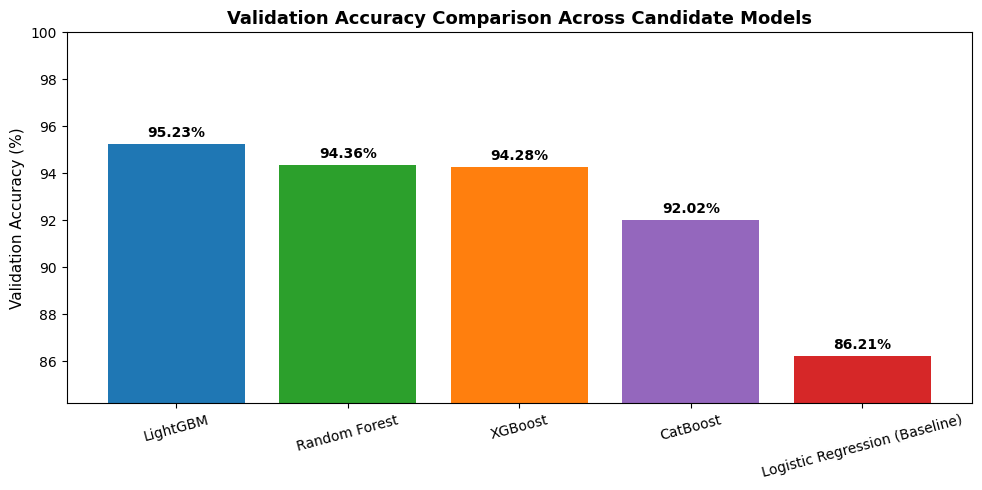

 Saved: /content/drive/MyDrive/Malicious project work/feature_names.pkl

--- Exporting All Project Artifacts to Google Drive ---
 Saved: /content/drive/MyDrive/Malicious project work/scaler.pkl
 Saved: /content/drive/MyDrive/Malicious project work/class_mapping.pkl
 Saved: /content/drive/MyDrive/Malicious project work/champion_lightgbm_model.pkl
 Saved: /content/drive/MyDrive/Malicious project work/model_logistic_regression_baseline.pkl
 Saved: /content/drive/MyDrive/Malicious project work/model_random_forest.pkl
 Saved: /content/drive/MyDrive/Malicious project work/model_xgboost.pkl
 Saved: /content/drive/MyDrive/Malicious project work/model_lightgbm.pkl
 Saved: /content/drive/MyDrive/Malicious project work/model_catboost.pkl

All model artifacts saved successfully to Google Drive!


In [22]:
# STEP 9: MODEL COMPARISON VISUALIZATION & SERIALIZATION

import matplotlib.pyplot as plt
import joblib
import pandas as pd
import os

# 1. Plot Model Comparison Bar Chart
comparison_df = summary_df.sort_values(by='Validation Accuracy (%)', ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(
    comparison_df['Model'],
    comparison_df['Validation Accuracy (%)'],
    color=['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']
)

min_acc = comparison_df['Validation Accuracy (%)'].min() - 2
plt.ylim(max(0, min_acc), 100)
plt.ylabel('Validation Accuracy (%)', fontsize=11)
plt.title('Validation Accuracy Comparison Across Candidate Models', fontsize=13, fontweight='bold')
plt.xticks(rotation=15)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.3, f"{yval:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 2. Define Output Google Drive Folder Path
SAVE_DIR = "/content/drive/MyDrive/Malicious project work/"
os.makedirs(SAVE_DIR, exist_ok=True)

# 3. Save Feature Names for Real-Time APK Vector Alignment
joblib.dump(X_train.columns.tolist(), os.path.join(SAVE_DIR, "feature_names.pkl"))
print(f" Saved: {os.path.join(SAVE_DIR, 'feature_names.pkl')}")

# 4. Serialize All Artifacts directly to Google Drive
class_mapping = {0: "Adware", 1: "Banking", 2: "SMS Malware", 3: "Riskware", 4: "Benign"}

export_artifacts = {
    "scaler.pkl": scaler,
    "class_mapping.pkl": class_mapping,
    "champion_lightgbm_model.pkl": champion_model
}

for model_name, model_obj in models.items():
    clean_filename = f"model_{model_name.lower().replace(' ', '_').replace('(', '').replace(')', '')}.pkl"
    export_artifacts[clean_filename] = model_obj

print("\n--- Exporting All Project Artifacts to Google Drive ---")
for filename, artifact_obj in export_artifacts.items():
    full_path = os.path.join(SAVE_DIR, filename)
    joblib.dump(artifact_obj, full_path)
    print(f" Saved: {full_path}")

print("\nAll model artifacts saved successfully to Google Drive!")

In [ ]:
# STEP 8.5: LIVE INFERENCE TEST FROM SERIALIZED ARTIFACTS


import joblib
import numpy as np

# 1. Load saved production artifacts
loaded_scaler = joblib.load("scaler.pkl")
loaded_model = joblib.load("champion_lightgbm_model.pkl")
class_map = joblib.load("class_mapping.pkl")

# 2. Pick a single sample from X_test (simulating incoming APK feature vector)
sample_idx = 2
sample_raw_features = X_test.iloc[[sample_idx]]  # Shape: (1, 470)
true_label_idx = y_test_encoded.iloc[sample_idx]

# 3. Model Inference Pipeline
# Tree model predicts directly on raw feature counts (or scaled if using distance models)
predicted_class_idx = loaded_model.predict(sample_raw_features)[0]
predicted_label_name = class_map[predicted_class_idx]
actual_label_name = class_map[true_label_idx]

print("--- Live Inference Verification ---")
print(f"Sample Index         : {sample_idx}")
print(f"Predicted Class      : {predicted_label_name} (Class ID: {predicted_class_idx})")
print(f"Actual Ground Truth  : {actual_label_name} (Class ID: {true_label_idx})")
print(f"Match Status         : {'✅ CORRECT' if predicted_class_idx == true_label_idx else '❌ MISMATCH'}")

--- Live Inference Verification ---
Sample Index         : 2
Predicted Class      : SMS Malware (Class ID: 2)
Actual Ground Truth  : SMS Malware (Class ID: 2)
Match Status         : ✅ CORRECT


In [ ]:
# Evaluate match rate across all 3,458 test samples
all_preds = loaded_model.predict(X_test)
correct_matches = (all_preds == y_test_encoded).sum()
total_samples = len(y_test_encoded)

print(f"Total Test Samples : {total_samples}")
print(f"Correct Matches    : {correct_matches}")
print(f"Overall Accuracy   : {(correct_matches / total_samples) * 100:.2f}%")

Total Test Samples : 3458
Correct Matches    : 3296
Overall Accuracy   : 95.32%
